# Driver-Informed Gaussian Processes for GPS-TEC at ADIS and BJCO
### Two-station comparison for the 23 June 2015 geomagnetic storm, with SYM-H / IMF Bz / E$_y$ solar-wind drivers

**Author:** Ezekwueme Augustine Elozana  ·  Extends: *Comparing the Ionospheric Effects of the 23rd June 2015 Geomagnetic Storm Event on Addis Ababa and Benin Ionospheric Stations* (Ezekwueme & Obiegbuna, University of Nigeria, Nsukka).

**What this notebook does**

1. Learns a **quiet-time TEC baseline** for each station with a Gaussian process (GP), with uncertainty.
2. Computes storm-time **ΔTEC = TEC − baseline**, as in the dissertation, but with an uncertainty band and z-scores.
3. Learns how ΔTEC depends on an **OMNI solar-wind driver** (−SYM-H, lagged) and on local daylight, with a second GP.
4. Compares **ADIS and BJCO**: best driver lag, peak ΔTEC (TECU and %), and held-out skill (RMSE and 95% coverage) of baseline-only versus driver-informed prediction.

> **Data note:** The notebook runs on **synthetic data** with arbitrary planted responses, so anyone can reproduce it and so the method can be tested against a known truth. These are **not scientific results**. Set `USE_REAL_DATA = True` and supply your VTEC and OMNI files (see the README) for real analysis.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel as C, RBF, ExpSineSquared, WhiteKernel)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
rng = np.random.default_rng(7)

## 1. Configuration

Stations and times follow the dissertation. Longitudes are **east-positive** (the dissertation's Methods give BJCO as 2.27°E). Check exact coordinates against each station's IGS site log.

In [2]:
USE_REAL_DATA = False

STATIONS = {                       # lon in degrees East
    "ADIS": {"lat": 8.90, "lon": 38.75, "file": "data/vtec_ADIS.csv"},
    "BJCO": {"lat": 6.22, "lon": 2.27,  "file": "data/vtec_BJCO.csv"},
}
OMNI_FILE = "data/omni.csv"        # columns: utc, sym_h, bz, vsw

START, END, STEP = "2015-06-18 00:00", "2015-06-25 00:00", "30min"
STEP_H = 0.5                       # hours per sample (must match STEP)
STORM_START = pd.Timestamp("2015-06-22 18:00")   # data before this = quiet-time training
QUIET_DAYS = None                  # or a list like ["2015-06-19", ...] to choose quiet days explicitly
TRAIN_STORM_UNTIL = pd.Timestamp("2015-06-24 00:00")  # storm-time split: fit before, test after
MAX_LAG_H = 8                      # driver-lag search range (hours)
N_RESTARTS = 5                     # GP optimiser restarts (lower = faster)

IDX = pd.date_range(START, END, freq=STEP, inclusive="left")
T_H = (IDX - IDX[0]).total_seconds().to_numpy() / 3600.0

## 2. Load data (real or synthetic)

**Expected CSV formats** (UTC timestamps):

- `vtec_<STATION>.csv`: `utc,vtec` (VTEC in TECU, for example resampled from GOPI GPS-TEC output)
- `omni.csv`: `utc,sym_h,bz,vsw` (SYM-H in nT, IMF Bz GSM in nT, solar-wind speed in km/s, for example from OMNIWeb)

The interplanetary electric field is computed as in the dissertation (Eq. 5): E$_y$ = −B$_z$ · V$_{sw}$ · 10⁻³ mV/m.

In [3]:
def daylight(idx, lon):
    # Smooth 0-1 daylight factor from local time (peak near 14 LT)
    ut = np.asarray(idx.hour) + np.asarray(idx.minute) / 60
    lt = (ut + lon / 15.0) % 24
    return (0.5 + 0.5 * np.cos(2 * np.pi * (lt - 14) / 24)) ** 1.5

def load_omni(path):
    df = pd.read_csv(path, parse_dates=["utc"]).set_index("utc")[["sym_h", "bz", "vsw"]]
    df = df.resample(STEP).mean().reindex(IDX).interpolate(limit=6)
    df["ey"] = -df["bz"] * df["vsw"] * 1e-3
    return df

def load_vtec(path):
    s = pd.read_csv(path, parse_dates=["utc"]).set_index("utc")["vtec"]
    return s.resample(STEP).mean().reindex(IDX)

# ---------- synthetic stand-ins (clearly NOT real observations) ----------
def synthetic_omni():
    t0, tm = pd.Timestamp("2015-06-22 18:30"), pd.Timestamp("2015-06-23 04:30")
    h = (IDX - t0).total_seconds().to_numpy() / 3600
    hm = (tm - t0).total_seconds() / 3600
    symh = np.where(h < 0, 0.0,
           np.where(h < hm, -200 * (np.clip(h, 0, None) / hm) ** 1.5,
                    -200 * np.exp(-(h - hm) / 12)))
    symh = symh + rng.normal(0, 2, len(IDX))
    hb = (IDX - pd.Timestamp("2015-06-22 23:00")).total_seconds().to_numpy() / 3600
    bz = 2 - 28 * np.exp(-0.5 * (hb / 2.5) ** 2) + rng.normal(0, 0.6, len(IDX))
    vsw = 450 + 290 / (1 + np.exp(-(h - 3) / 2)) + rng.normal(0, 8, len(IDX))
    df = pd.DataFrame({"sym_h": symh, "bz": bz, "vsw": vsw}, index=IDX)
    df["ey"] = -df["bz"] * df["vsw"] * 1e-3
    return df

def synthetic_station(lon, base, amp, gain, lag_h, omni):
    day = daylight(IDX, lon)
    codes = pd.factorize(IDX.date)[0]
    scale = 1 + 0.03 * rng.standard_normal(codes.max() + 1)
    quiet = base + amp * day * scale[codes]
    s_lag = omni["sym_h"].shift(int(round(lag_h / STEP_H))).fillna(0).to_numpy()
    dtec = gain * (-s_lag / 200.0) * (0.3 + 0.7 * day)       # planted storm response
    y = quiet + dtec + rng.normal(0, 1.0, len(IDX))
    y[rng.random(len(IDX)) < 0.08] = np.nan                   # data gaps
    return pd.Series(y, index=IDX)

if USE_REAL_DATA:
    omni = load_omni(OMNI_FILE)
    tec = {k: load_vtec(v["file"]) for k, v in STATIONS.items()}
else:
    omni = synthetic_omni()
    # arbitrary planted gains and lags, used only to test whether the method recovers them
    tec = {"ADIS": synthetic_station(38.75, 8, 30, gain=10, lag_h=2.0, omni=omni),
           "BJCO": synthetic_station(2.27, 10, 36, gain=14, lag_h=3.5, omni=omni)}
    PLANTED = {"ADIS": 2.0, "BJCO": 3.5}

print({k: f"{v.notna().sum()} samples" for k, v in tec.items()}, "| OMNI rows:", len(omni))

{'ADIS': '311 samples', 'BJCO': '311 samples'} | OMNI rows: 336


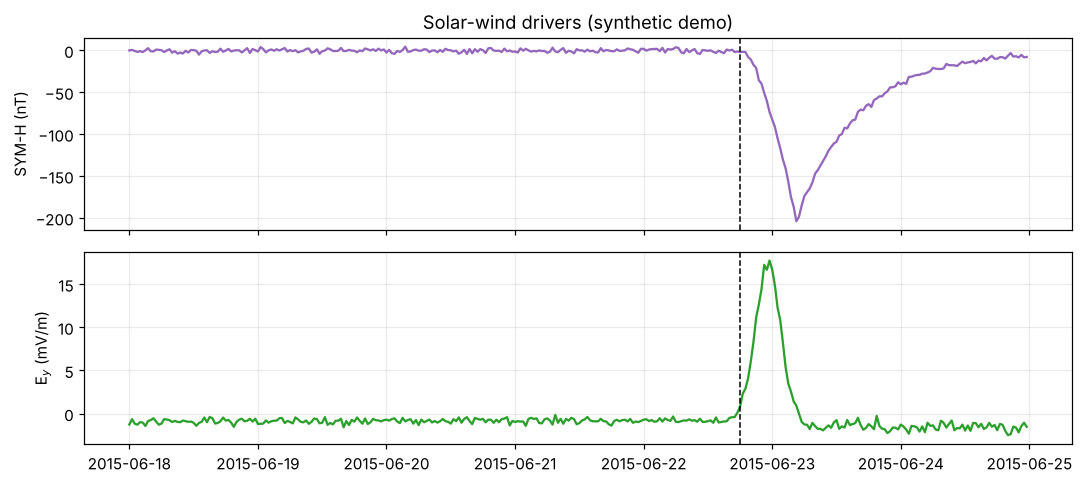

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
ax[0].plot(omni.index, omni["sym_h"], color="tab:purple"); ax[0].set_ylabel("SYM-H (nT)")
ax[1].plot(omni.index, omni["ey"], color="tab:green");     ax[1].set_ylabel("E$_y$ (mV/m)")
for a in ax: a.axvline(STORM_START, ls="--", color="k", lw=1)
ax[0].set_title("Solar-wind drivers" + ("" if USE_REAL_DATA else " (synthetic demo)"))
plt.tight_layout(); plt.show()

## 3. Stage 1: quiet-time GP baseline

The kernel encodes a ~24 h cycle (`ExpSineSquared`), letting it drift slowly (`RBF`), plus a slow trend and white noise. The baseline is trained **only on quiet time**. Subtracting it from observations gives ΔTEC = DTEC − QTEC as in Eq. (3) of the dissertation, now with an uncertainty.

In [5]:
def build_kernel():
    diurnal = (C(100.0, (1, 1e4))
               * ExpSineSquared(length_scale=1.0, periodicity=24.0,
                                length_scale_bounds=(0.3, 10), periodicity_bounds=(23.0, 25.0))
               * RBF(length_scale=72.0, length_scale_bounds=(24, 2000)))
    trend = C(10.0, (1e-3, 1e3)) * RBF(length_scale=48.0, length_scale_bounds=(12, 500))
    noise = WhiteKernel(noise_level=0.01, noise_level_bounds=(1e-4, 1))
    return diurnal + trend + noise

def quiet_mask(idx):
    if QUIET_DAYS is None:
        return idx < STORM_START
    return pd.Index(idx.strftime("%Y-%m-%d")).isin(QUIET_DAYS)

def fit_baseline(y):
    m = quiet_mask(IDX) & y.notna().to_numpy()
    gp = GaussianProcessRegressor(kernel=build_kernel(), normalize_y=True,
                                  n_restarts_optimizer=N_RESTARTS, random_state=0)
    gp.fit(T_H[m].reshape(-1, 1), y.to_numpy()[m])
    mu, sd = gp.predict(T_H.reshape(-1, 1), return_std=True)
    noise_sd = np.sqrt(gp.kernel_.k2.noise_level) * gp._y_train_std   # observation-noise sd (TECU)
    latent_sd = np.sqrt(np.clip(sd ** 2 - noise_sd ** 2, 0, None))
    return gp, mu, sd, latent_sd, noise_sd

base = {k: fit_baseline(v) for k, v in tec.items()}
for k, (gp, mu, sd, lsd, nsd) in base.items():
    print(f"{k}: noise sd ≈ {nsd:.2f} TECU")

ADIS: noise sd ≈ 0.95 TECU
BJCO: noise sd ≈ 1.00 TECU


## 4. Stage 2: driver-informed model of ΔTEC

On storm-time data, a second GP maps **two physically motivated inputs** to the residual ΔTEC:

- the lagged driver **−SYM-H(t − lag)**, a ring-current proxy (use `ey` instead to test the interplanetary electric field);
- the **local daylight factor**, since ionospheric response depends on local time.

The lag is chosen on the *training* segment only (no peeking at the test segment) by maximising the correlation between ΔTEC and the lagged, daylight-weighted driver. An ARD kernel learns how strongly each input matters.

In [6]:
DRIVER = "sym_h"        # try "ey" as well (sign handled below)
SIGN = -1.0 if DRIVER == "sym_h" else 1.0     # use -SYM-H so a stronger storm = larger value

def lagged_driver(lag_h):
    s = omni[DRIVER].shift(int(round(lag_h / STEP_H))).bfill().fillna(0.0).to_numpy()
    return SIGN * s / (100.0 if DRIVER == "sym_h" else 10.0)

storm_mask = (IDX >= STORM_START)
train_mask = storm_mask & (IDX < TRAIN_STORM_UNTIL)
test_mask  = IDX >= TRAIN_STORM_UNTIL

def analyse(name, y, lon):
    gp0, mu_b, sd_b, lsd_b, _ = base[name]
    r = y.to_numpy() - mu_b                      # ΔTEC (observations minus baseline)
    day = daylight(IDX, lon)
    ok = y.notna().to_numpy()

    # lag scan on the training segment only
    lags = np.arange(0, MAX_LAG_H + 0.01, 0.5)
    cors = []
    for L in lags:
        f = lagged_driver(L) * (0.3 + 0.7 * day)
        m = train_mask & ok
        cors.append(np.corrcoef(f[m], r[m])[0, 1])
    best_lag = lags[int(np.nanargmax(cors))]

    X = np.c_[lagged_driver(best_lag), day]
    k = C(1.0, (1e-2, 1e2)) * RBF([1.0, 1.0], (0.05, 20)) + WhiteKernel(0.1, (1e-4, 1))
    # Scale (but do not centre) the target so the GP prior mean is ΔTEC = 0 (no driver, no storm effect)
    gp = GaussianProcessRegressor(kernel=k, normalize_y=False, n_restarts_optimizer=N_RESTARTS, random_state=0)
    mtr = train_mask & ok
    sc = np.std(r[mtr])
    gp.fit(X[mtr], r[mtr] / sc)
    mu2, sd2 = gp.predict(X, return_std=True)
    mu2, sd2 = mu2 * sc, sd2 * sc
    sd_tot = np.sqrt(sd2 ** 2 + lsd_b ** 2)      # add baseline uncertainty in quadrature

    mte = test_mask & ok
    def skill(pred, sd):
        err = r[mte] - pred[mte]
        return {"RMSE": float(np.sqrt(np.mean(err ** 2))),
                "cov95": float(np.mean(np.abs(err) <= 1.96 * sd[mte]))}
    s_base = skill(np.zeros_like(r), sd_b)
    s_drv  = skill(mu2, sd_tot)

    stm = storm_mask & ok & (mu_b > 1)
    i_pk = np.argmax(np.where(stm, r, -np.inf))
    z = r / sd_b
    return dict(name=name, r=r, mu_b=mu_b, sd_b=sd_b, mu2=mu2, sd_tot=sd_tot, z=z, ok=ok,
                lags=lags, cors=np.array(cors), best_lag=best_lag, gp2=gp,
                s_base=s_base, s_drv=s_drv,
                peak_tecu=float(r[i_pk]), peak_pct=float(100 * r[i_pk] / mu_b[i_pk]),
                peak_time=IDX[i_pk], flagged=float(np.mean(np.abs(z[storm_mask & ok]) > 2)))

res = {k: analyse(k, tec[k], STATIONS[k]["lon"]) for k in STATIONS}
for k, v in res.items():
    print(f"{k}: best lag = {v['best_lag']:.1f} h | learned kernel: {v['gp2'].kernel_}")
if not USE_REAL_DATA:
    print("Planted lags (synthetic truth):", PLANTED)

ADIS: best lag = 2.0 h | learned kernel: 1.31**2 * RBF(length_scale=[0.93, 0.539]) + WhiteKernel(noise_level=0.158)
BJCO: best lag = 3.5 h | learned kernel: 1.83**2 * RBF(length_scale=[1.73, 0.925]) + WhiteKernel(noise_level=0.0713)
Planted lags (synthetic truth): {'ADIS': 2.0, 'BJCO': 3.5}


## 5. Results: figures and two-station comparison

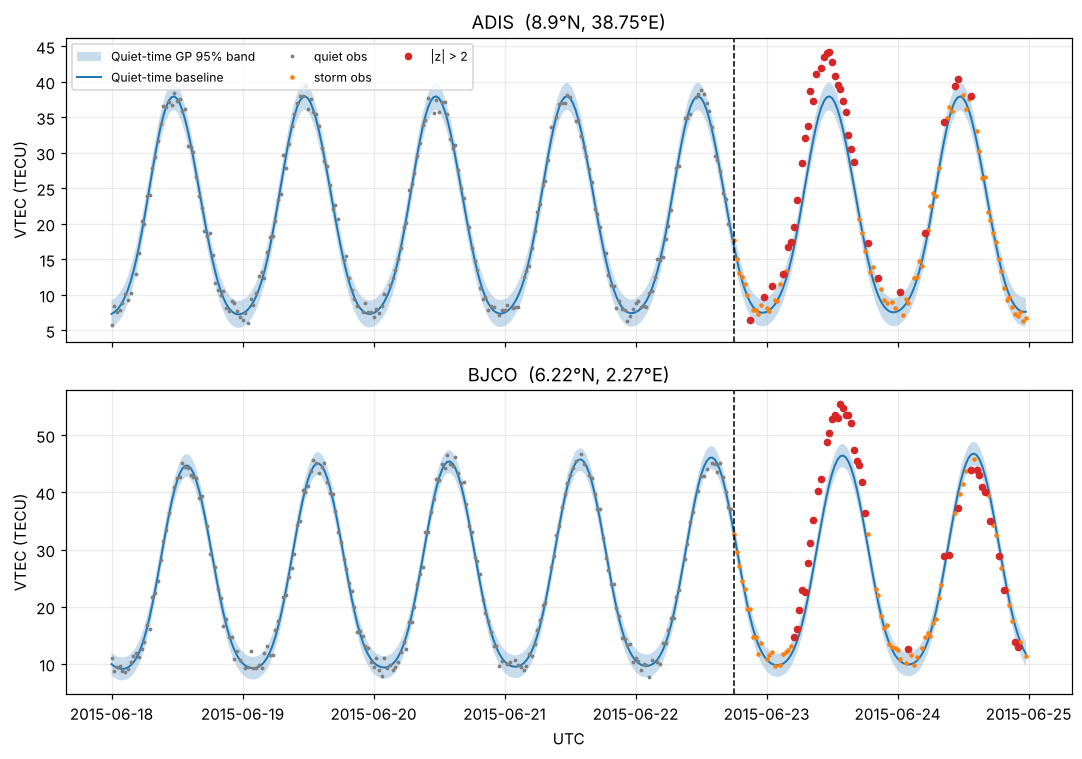

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (k, v) in zip(axes, res.items()):
    ax.fill_between(IDX, v["mu_b"] - 1.96 * v["sd_b"], v["mu_b"] + 1.96 * v["sd_b"], alpha=0.25,
                    label="Quiet-time GP 95% band")
    ax.plot(IDX, v["mu_b"], lw=1.3, label="Quiet-time baseline")
    q = quiet_mask(IDX) & v["ok"]
    s = storm_mask & v["ok"]
    out = s & (np.abs(v["z"]) > 2)
    ax.plot(IDX[q], tec[k].to_numpy()[q], ".", ms=3, color="gray", label="quiet obs")
    ax.plot(IDX[s & ~out], tec[k].to_numpy()[s & ~out], ".", ms=4, color="tab:orange", label="storm obs")
    ax.plot(IDX[out], tec[k].to_numpy()[out], "o", ms=4, color="tab:red", label="|z| > 2")
    ax.axvline(STORM_START, ls="--", color="k", lw=1)
    ax.set(ylabel="VTEC (TECU)", title=f"{k}  ({STATIONS[k]['lat']}°N, {STATIONS[k]['lon']}°E)")
axes[0].legend(ncol=3, fontsize=8, loc="upper left")
axes[1].set_xlabel("UTC")
plt.tight_layout(); plt.show()

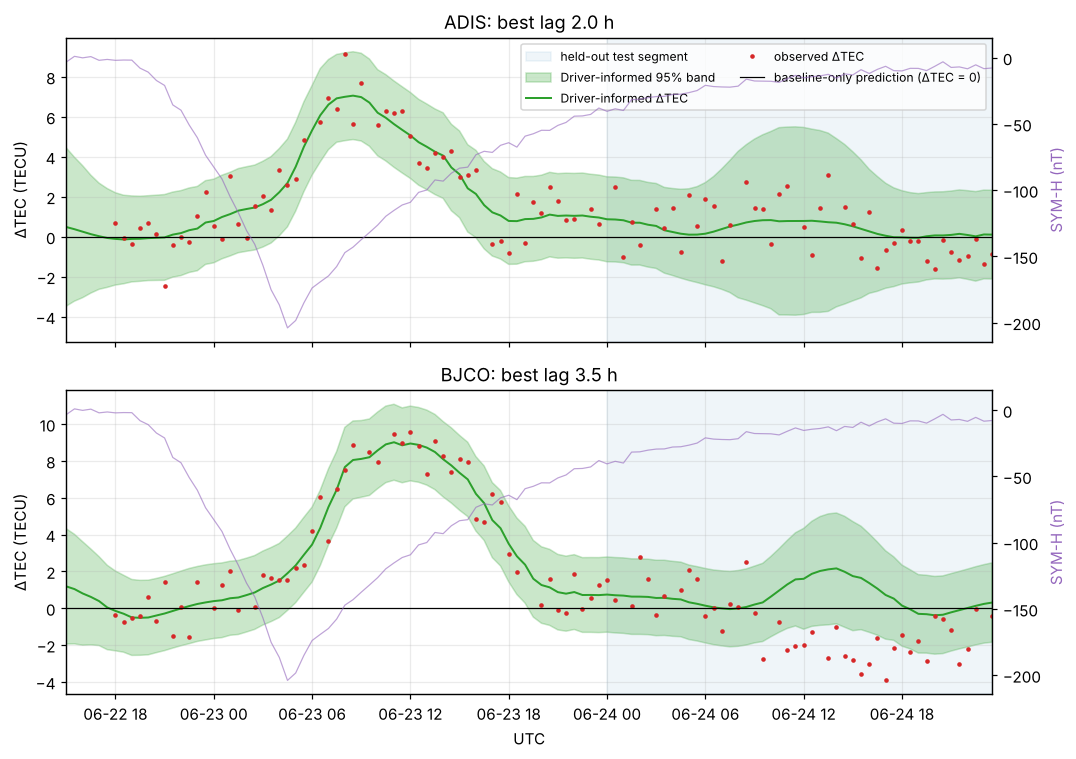

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (k, v) in zip(axes, res.items()):
    ax.axvspan(TRAIN_STORM_UNTIL, IDX[-1], color="tab:blue", alpha=0.07, label="held-out test segment")
    ax.fill_between(IDX, v["mu2"] - 1.96 * v["sd_tot"], v["mu2"] + 1.96 * v["sd_tot"], alpha=0.25,
                    color="tab:green", label="Driver-informed 95% band")
    ax.plot(IDX, v["mu2"], color="tab:green", lw=1.3, label="Driver-informed ΔTEC")
    ax.plot(IDX[storm_mask & v["ok"]], v["r"][storm_mask & v["ok"]], ".", ms=4, color="tab:red", label="observed ΔTEC")
    ax.axhline(0, color="k", lw=0.8, label="baseline-only prediction (ΔTEC = 0)")
    ax2 = ax.twinx(); ax2.plot(IDX, omni["sym_h"], color="tab:purple", lw=0.8, alpha=0.6)
    ax2.set_ylabel("SYM-H (nT)", color="tab:purple"); ax2.grid(False)
    ax.set(ylabel="ΔTEC (TECU)", xlim=(STORM_START - pd.Timedelta("3h"), IDX[-1]),
           title=f"{k}: best lag {v['best_lag']:.1f} h")
axes[0].legend(ncol=2, fontsize=8, loc="upper right")
axes[1].set_xlabel("UTC")
plt.tight_layout(); plt.show()

In [9]:
rows = []
for k, v in res.items():
    rows.append({
        "Station": k,
        "Best driver lag (h)": float(v["best_lag"]),
        "Peak ΔTEC (TECU)": round(v["peak_tecu"], 1),
        "Peak ΔTEC (% of baseline)": round(v["peak_pct"], 0),
        "Peak time (UTC)": v["peak_time"].strftime("%d %b %H:%M"),
        "Storm samples |z|>2": f"{v['flagged']:.0%}",
        "Test RMSE: baseline-only": round(v["s_base"]["RMSE"], 2),
        "Test RMSE: driver-informed": round(v["s_drv"]["RMSE"], 2),
        "Test 95% coverage: baseline-only": f"{v['s_base']['cov95']:.0%}",
        "Test 95% coverage: driver-informed": f"{v['s_drv']['cov95']:.0%}",
    })
table = pd.DataFrame(rows).set_index("Station").T
display(table)

Station,ADIS,BJCO
Best driver lag (h),2.0,3.5
Peak ΔTEC (TECU),9.1,9.5
Peak ΔTEC (% of baseline),31.0,22.0
Peak time (UTC),23 Jun 08:00,23 Jun 12:00
Storm samples |z|>2,35%,40%
Test RMSE: baseline-only,1.35,1.9
Test RMSE: driver-informed,1.18,2.51
Test 95% coverage: baseline-only,86%,65%
Test 95% coverage: driver-informed,100%,53%


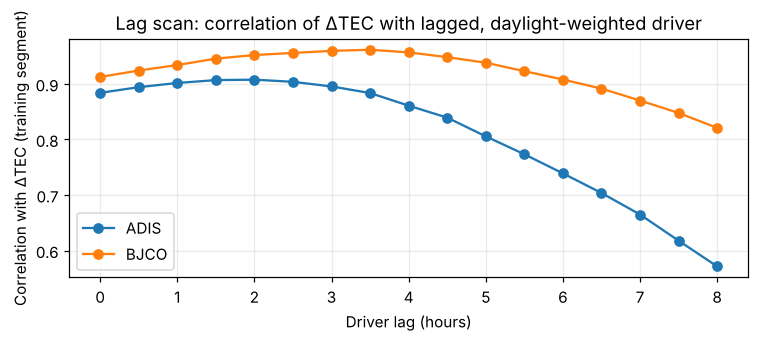

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, v in res.items():
    ax.plot(v["lags"], v["cors"], "o-", label=k)
ax.set(xlabel="Driver lag (hours)", ylabel="Correlation with ΔTEC (training segment)",
       title="Lag scan: correlation of ΔTEC with lagged, daylight-weighted driver")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Reading the results (and the limits)

- **Absolute versus relative change.** The dissertation compares TECU values and percentage changes; these can rank the stations differently (a smaller absolute change on a lower baseline can be a larger percentage). The table reports both, using the GP baseline as the denominator.
- **Skill is judged on held-out data.** The driver-informed model is compared with the baseline-only prediction (ΔTEC = 0) on a later, unseen time segment. Check both RMSE and whether the 95% band covers about 95% of the points.
- **Synthetic validation.** With synthetic data the true lags are known, so the lag scan acts as a sanity check, and Section 7 repeats the experiment over several seeds. In a single run the driver-informed model can lose at one station, because day-to-day baseline error is not driver-related; the seed average is more informative. None of this shows the method works on real storms.
- **One storm, two stations.** The conclusions from the real data are descriptive for this single event. Generalising needs many storms and many stations.
- **Quiet-day choice** (`QUIET_DAYS`) strongly affects ΔTEC. Repeat the analysis with different quiet-day sets and report the spread.
- **Simplifications.** Baseline uncertainty is added in quadrature to the stage-2 uncertainty, and a single lag is used per station. A joint model would be better.
- **Next steps:** add other drivers (Ey, solar-wind pressure, AE), test a physics-informed mean function, and extend to more stations and storms.

## 7. Robustness check (synthetic data only)

A single run can mislead, especially with one storm and one test segment. Here the whole synthetic experiment is repeated with different random seeds (noise, gaps and day-to-day variability change; the planted lags stay fixed). Run this cell **last**, because it replaces the notebook's working variables.

In [11]:
if USE_REAL_DATA:
    print("Skipped: this check uses synthetic data with known planted lags.")
else:
    N_RESTARTS = 2
    rows = []
    for seed in range(8):
        rng = np.random.default_rng(seed)
        omni = synthetic_omni()
        tec = {"ADIS": synthetic_station(38.75, 8, 30, gain=10, lag_h=2.0, omni=omni),
               "BJCO": synthetic_station(2.27, 10, 36, gain=14, lag_h=3.5, omni=omni)}
        base = {k: fit_baseline(v) for k, v in tec.items()}
        for k in STATIONS:
            v = analyse(k, tec[k], STATIONS[k]["lon"])
            rows.append({"seed": seed, "station": k, "lag error (h)": v["best_lag"] - PLANTED[k],
                         "RMSE base-only": v["s_base"]["RMSE"], "RMSE driver": v["s_drv"]["RMSE"],
                         "cov95 base-only": v["s_base"]["cov95"], "cov95 driver": v["s_drv"]["cov95"]})
    rob = pd.DataFrame(rows)
    summary = rob.groupby("station").agg(
        mean_abs_lag_error_h=("lag error (h)", lambda x: np.mean(np.abs(x))),
        mean_RMSE_base=("RMSE base-only", "mean"), mean_RMSE_driver=("RMSE driver", "mean"),
        mean_cov95_base=("cov95 base-only", "mean"), mean_cov95_driver=("cov95 driver", "mean")).round(2)
    wins = rob.assign(win=rob["RMSE driver"] < rob["RMSE base-only"]).groupby("station")["win"].sum()
    summary["seeds driver wins (of 8)"] = wins
    display(summary)

,mean_abs_lag_error_h,mean_RMSE_base,mean_RMSE_driver,mean_cov95_base,mean_cov95_driver,seeds driver wins (of 8)
station,,,,,,
ADIS,0.56,1.50,1.33,0.90,0.98,5
BJCO,0.56,1.81,1.53,0.83,0.91,7
